In [52]:
#그래프관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler


In [53]:
df = pd.read_csv('data/study.csv',sep='\t')
df.head()

,our,score
0,0.5,10
1,1.2,8
2,1.8,14
3,2.4,26
4,2.6,22


In [54]:
data = df.iloc[:,:-1].values
# label = df.iloc[:,1:].values
# data[:3]
# label[:3]
label = df.iloc[:,-1].values


In [55]:
train_data,test_data,train_label,test_label = train_test_split(data,label)

In [56]:
train_poly = np.column_stack((train_data**2,train_data))
test_poly = np.column_stack((test_data**2,test_data))

In [57]:
lr = LinearRegression()
lr.fit(train_poly,train_label)
predict = lr.predict(test_poly)
print("예측점수 : ",predict) 
score = lr.score(train_poly,train_label)
score2 = lr.score(test_poly,test_label)
print("train정답률 : ",score)
print("test정답률 : ",score2)

예측점수 :  [88.63681563 74.48448307 65.45796899 42.83535206 34.80891286]
train정답률 :  0.9695285040298219
test정답률 :  0.8263736836703675


In [58]:
print(lr.coef_,lr.intercept_)

[-0.24773821 13.22528304] -4.9751535739652795


In [59]:
point = np.arange(1,11)
point

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10])

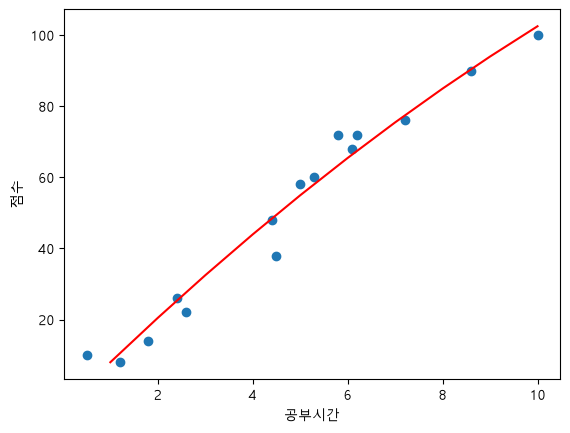

In [62]:
plt.scatter(train_data,train_label)
plt.plot(point,lr.coef_[0]*point**2+point*lr.coef_[1]+lr.intercept_,color='r')
plt.xlabel('공부시간')
plt.ylabel('점수')
plt.show()